Dataset loaded successfully
Training images: (10000, 28, 28, 1)
Testing images: (10000, 28, 28, 1)


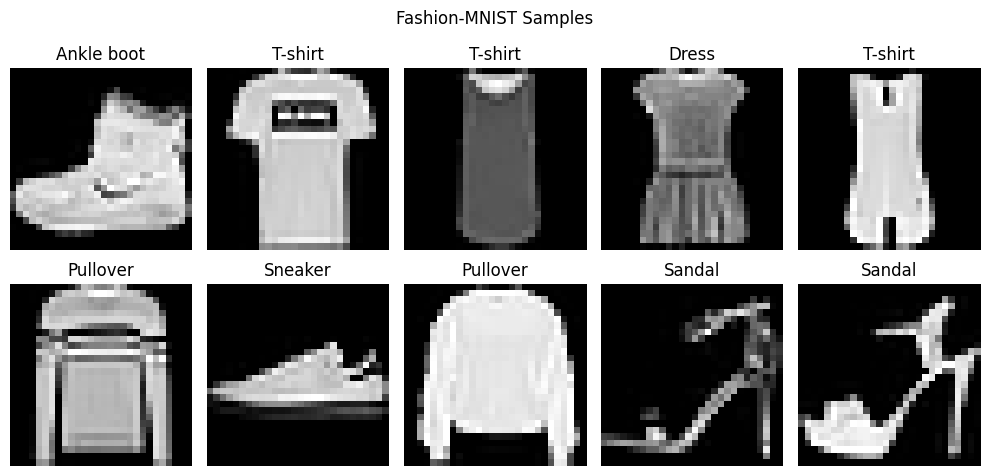


========== VAE TRAINING ==========
Epoch 1/5 | Total Loss: 373.732 | Reconstruction: 365.525 | KL: 8.207
Epoch 2/5 | Total Loss: 296.255 | Reconstruction: 289.615 | KL: 6.639
Epoch 3/5 | Total Loss: 286.536 | Reconstruction: 280.098 | KL: 6.438
Epoch 4/5 | Total Loss: 282.465 | Reconstruction: 276.239 | KL: 6.226
Epoch 5/5 | Total Loss: 279.119 | Reconstruction: 272.950 | KL: 6.169


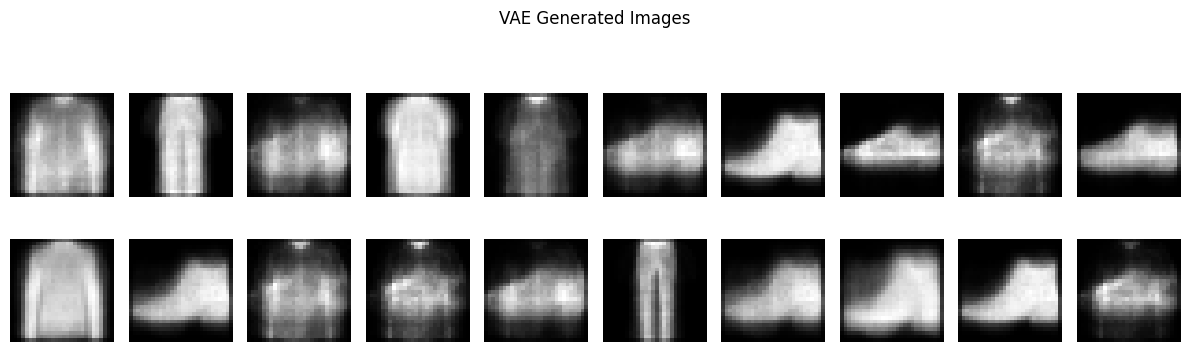

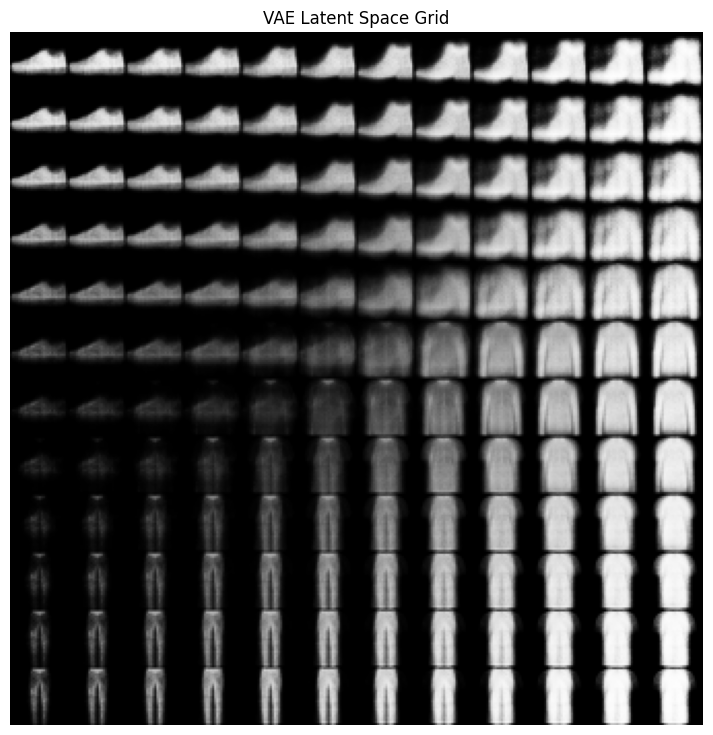

/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(



========== DCGAN TRAINING ==========
Epoch 1/5 | G Loss: 0.7909 | D Loss: 0.9624
Epoch 2/5 | G Loss: 0.7895 | D Loss: 1.2391
Epoch 3/5 | G Loss: 0.7771 | D Loss: 1.2949
Epoch 4/5 | G Loss: 0.7564 | D Loss: 1.3129
Epoch 5/5 | G Loss: 0.7648 | D Loss: 1.3039


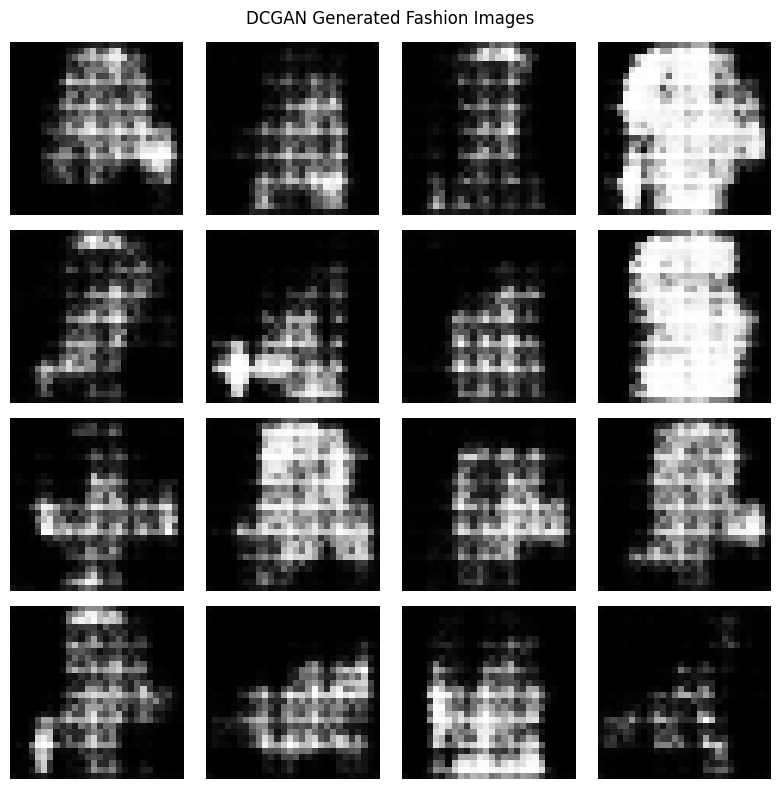

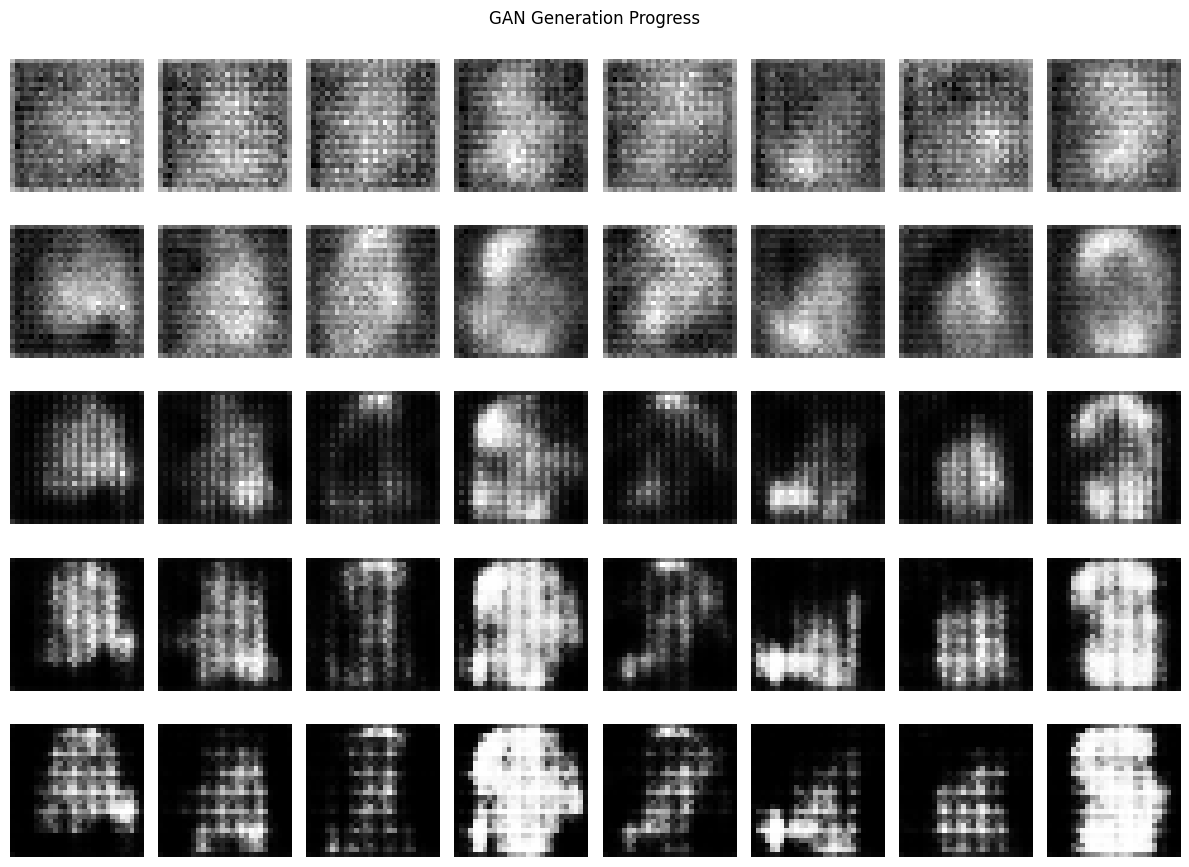

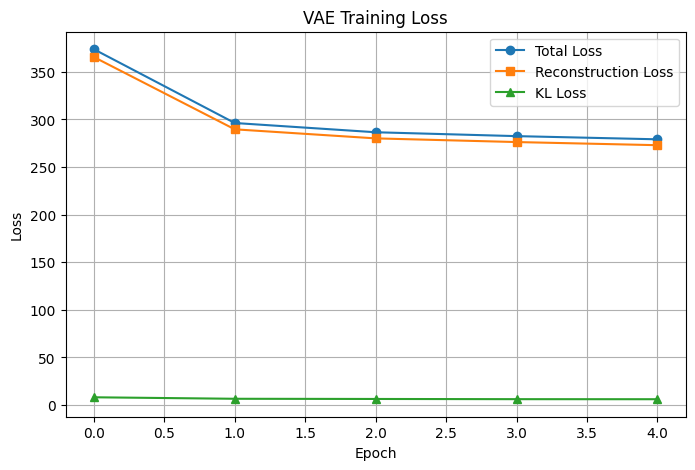

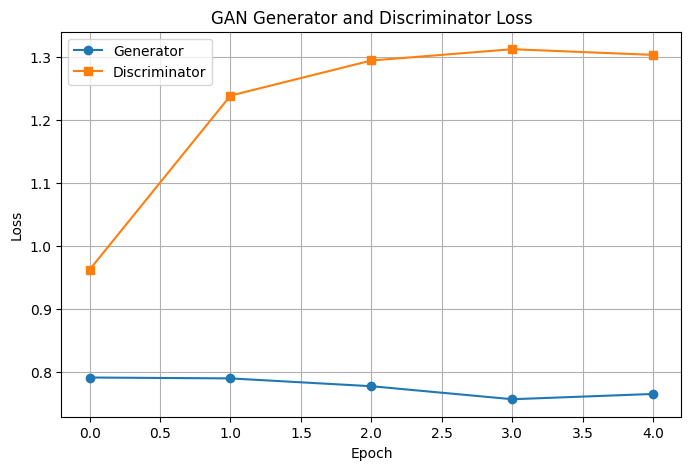

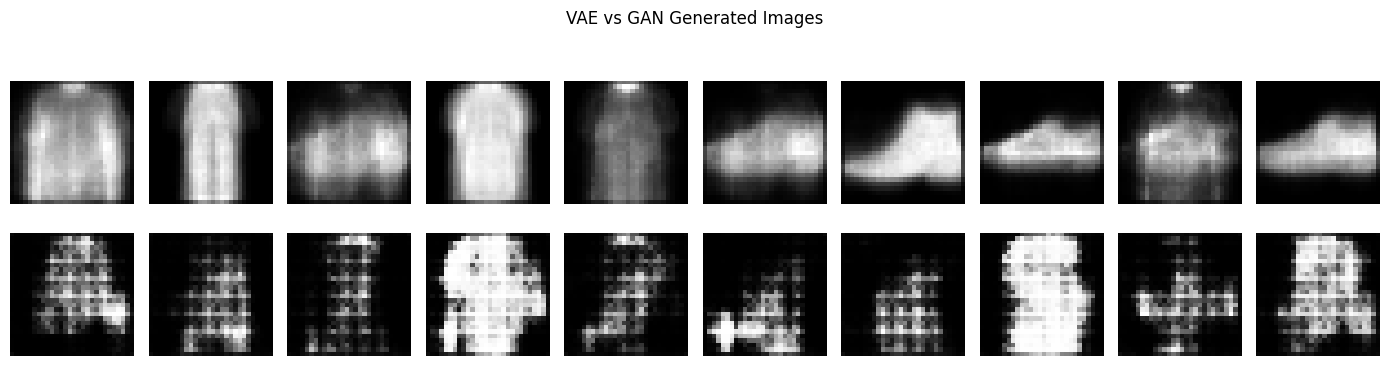


EXPERIMENT 29 COMPLETED
VAE training completed successfully.
DCGAN training completed successfully.
Generated fashion images displayed.
Latent-space visualization generated.
Training-loss graphs generated.
VAE and GAN comparison displayed.


In [19]:

# ============================================================
# EXPERIMENT 29: VAE / GAN SAMPLE GENERATION
# Fashion-MNIST | Complete Google Colab Code | Single Cell
# ============================================================

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)

# ============================================================
# 1. LOAD DATASET
# ============================================================
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

# Training subset for faster Colab execution
train_images = x_train[:10000]

# GAN images scaled to [-1, 1]
gan_images = train_images * 2.0 - 1.0

print("Dataset loaded successfully")
print("Training images:", train_images.shape)
print("Testing images:", x_test.shape)

# ============================================================
# 2. DISPLAY REAL IMAGES
# ============================================================
class_names = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i].squeeze(), cmap="gray")
    ax.set_title(class_names[y_train[i]])
    ax.axis("off")

plt.suptitle("Fashion-MNIST Samples")
plt.tight_layout()
plt.show()

# ============================================================
# 3. BUILD VAE ENCODER
# ============================================================
LATENT_DIM = 2

encoder_input = tf.keras.Input(shape=(28, 28, 1))

x = tf.keras.layers.Flatten()(encoder_input)
x = tf.keras.layers.Dense(256, activation="relu")(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)

z_mean = tf.keras.layers.Dense(LATENT_DIM)(x)
z_log_var = tf.keras.layers.Dense(LATENT_DIM)(x)

def sampling(args):
    mean, log_var = args
    epsilon = tf.random.normal(tf.shape(mean))
    return mean + tf.exp(0.5 * log_var) * epsilon

z = tf.keras.layers.Lambda(sampling)([z_mean, z_log_var])

encoder = tf.keras.Model(
    encoder_input, [z_mean, z_log_var, z], name="Encoder"
)

# ============================================================
# 4. BUILD VAE DECODER
# ============================================================
decoder_input = tf.keras.Input(shape=(LATENT_DIM,))

d = tf.keras.layers.Dense(128, activation="relu")(decoder_input)
d = tf.keras.layers.Dense(256, activation="relu")(d)
d = tf.keras.layers.Dense(784, activation="sigmoid")(d)
decoder_output = tf.keras.layers.Reshape((28, 28, 1))(d)

decoder = tf.keras.Model(
    decoder_input, decoder_output, name="Decoder"
)

# ============================================================
# 5. TRAIN VAE
# ============================================================
vae_optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

vae_epochs = 5
batch_size = 128

dataset = tf.data.Dataset.from_tensor_slices(
    train_images
).shuffle(10000).batch(batch_size)

vae_total_losses = []
vae_recon_losses = []
vae_kl_losses = []

print("\n========== VAE TRAINING ==========")

for epoch in range(vae_epochs):

    total_losses = []
    recon_losses = []
    kl_losses = []

    for batch in dataset:

        with tf.GradientTape() as tape:

            mean, log_var, z_sample = encoder(batch, training=True)
            reconstructed = decoder(z_sample, training=True)

            # Reconstruction loss
            bce = tf.keras.backend.binary_crossentropy(
                batch, reconstructed
            )

            recon_loss = tf.reduce_mean(
                tf.reduce_sum(bce, axis=(1, 2))
            )

            # KL divergence
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + log_var
                    - tf.square(mean)
                    - tf.exp(log_var),
                    axis=1
                )
            )

            total_loss = recon_loss + kl_loss

        variables = encoder.trainable_variables + decoder.trainable_variables

        gradients = tape.gradient(total_loss, variables)

        vae_optimizer.apply_gradients(
            zip(gradients, variables)
        )

        total_losses.append(float(total_loss))
        recon_losses.append(float(recon_loss))
        kl_losses.append(float(kl_loss))

    vae_total_losses.append(np.mean(total_losses))
    vae_recon_losses.append(np.mean(recon_losses))
    vae_kl_losses.append(np.mean(kl_losses))

    print(
        f"Epoch {epoch+1}/{vae_epochs} | "
        f"Total Loss: {np.mean(total_losses):.3f} | "
        f"Reconstruction: {np.mean(recon_losses):.3f} | "
        f"KL: {np.mean(kl_losses):.3f}"
    )

# ============================================================
# 6. GENERATE VAE IMAGES
# ============================================================
vae_noise = np.random.normal(
    size=(20, LATENT_DIM)
).astype("float32")

vae_samples = decoder.predict(vae_noise, verbose=0)

fig, axes = plt.subplots(2, 10, figsize=(12, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(vae_samples[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.suptitle("VAE Generated Images")
plt.tight_layout()
plt.show()

# ============================================================
# 7. VAE LATENT SPACE GRID
# ============================================================
grid_size = 12
grid_range = 3

grid_x = np.linspace(-grid_range, grid_range, grid_size)
grid_y = np.linspace(-grid_range, grid_range, grid_size)

latent_grid = np.array(
    [[xx, yy] for yy in grid_y for xx in grid_x],
    dtype=np.float32
)

grid_generated = decoder.predict(latent_grid, verbose=0)

canvas = np.zeros((28 * grid_size, 28 * grid_size))

for i in range(grid_size):
    for j in range(grid_size):
        idx = i * grid_size + j

        canvas[
            i*28:(i+1)*28,
            j*28:(j+1)*28
        ] = grid_generated[idx].squeeze()

plt.figure(figsize=(9, 9))
plt.imshow(canvas, cmap="gray")
plt.title("VAE Latent Space Grid")
plt.axis("off")
plt.show()

# ============================================================
# 8. BUILD DCGAN GENERATOR
# ============================================================
NOISE_DIM = 100

generator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(NOISE_DIM,)),

    tf.keras.layers.Dense(7 * 7 * 128, use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.Reshape((7, 7, 128)),

    tf.keras.layers.Conv2DTranspose(
        64, 4, strides=2, padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.Conv2DTranspose(
        1, 4, strides=2, padding="same", activation="tanh"
    )
], name="Generator")

# ============================================================
# 9. BUILD DCGAN DISCRIMINATOR
# ============================================================
discriminator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        64, 4, strides=2, padding="same"
    ),
    tf.keras.layers.LeakyReLU(alpha=0.2),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Conv2D(
        128, 4, strides=2, padding="same"
    ),
    tf.keras.layers.LeakyReLU(alpha=0.2),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1)
], name="Discriminator")

# ============================================================
# 10. GAN LOSS AND OPTIMIZERS
# ============================================================
cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

g_optimizer = tf.keras.optimizers.Adam(
    0.0002, beta_1=0.5
)

d_optimizer = tf.keras.optimizers.Adam(
    0.0002, beta_1=0.5
)

# ============================================================
# 11. GAN TRAINING STEP
# ============================================================
@tf.function
def train_gan_step(real_batch):

    batch_size_now = tf.shape(real_batch)[0]
    noise = tf.random.normal((batch_size_now, NOISE_DIM))

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        fake_images = generator(noise, training=True)

        real_output = discriminator(real_batch, training=True)
        fake_output = discriminator(fake_images, training=True)

        generator_loss = cross_entropy(
            tf.ones_like(fake_output), fake_output
        )

        real_loss = cross_entropy(
            tf.ones_like(real_output), real_output
        )

        fake_loss = cross_entropy(
            tf.zeros_like(fake_output), fake_output
        )

        discriminator_loss = real_loss + fake_loss

    gen_gradients = gen_tape.gradient(
        generator_loss, generator.trainable_variables
    )

    disc_gradients = disc_tape.gradient(
        discriminator_loss, discriminator.trainable_variables
    )

    g_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )

    d_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    return generator_loss, discriminator_loss

# ============================================================
# 12. TRAIN GAN
# ============================================================
gan_dataset = tf.data.Dataset.from_tensor_slices(
    gan_images
).shuffle(10000).batch(128, drop_remainder=True)

GAN_EPOCHS = 5

generator_losses = []
discriminator_losses = []
epoch_generated_images = []

fixed_noise = tf.random.normal((16, NOISE_DIM))

print("\n========== DCGAN TRAINING ==========")

for epoch in range(GAN_EPOCHS):

    g_epoch_losses = []
    d_epoch_losses = []

    for real_batch in gan_dataset:

        g_loss, d_loss = train_gan_step(real_batch)

        g_epoch_losses.append(float(g_loss))
        d_epoch_losses.append(float(d_loss))

    avg_g_loss = np.mean(g_epoch_losses)
    avg_d_loss = np.mean(d_epoch_losses)

    generator_losses.append(avg_g_loss)
    discriminator_losses.append(avg_d_loss)

    print(
        f"Epoch {epoch+1}/{GAN_EPOCHS} | "
        f"G Loss: {avg_g_loss:.4f} | "
        f"D Loss: {avg_d_loss:.4f}"
    )

    generated = generator(
        fixed_noise, training=False
    ).numpy()

    epoch_generated_images.append(generated)

# ============================================================
# 13. DISPLAY FINAL GAN IMAGES
# ============================================================
final_generated = epoch_generated_images[-1]

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):

    image = (final_generated[i].squeeze() + 1) / 2
    image = np.clip(image, 0, 1)

    ax.imshow(image, cmap="gray")
    ax.axis("off")

plt.suptitle("DCGAN Generated Fashion Images")
plt.tight_layout()
plt.show()

# ============================================================
# 14. GAN GENERATION PROGRESS
# ============================================================
fig, axes = plt.subplots(
    GAN_EPOCHS, 8, figsize=(12, 9)
)

for epoch in range(GAN_EPOCHS):
    for i in range(8):

        image = epoch_generated_images[epoch][i].squeeze()
        image = np.clip((image + 1) / 2, 0, 1)

        axes[epoch, i].imshow(image, cmap="gray")
        axes[epoch, i].axis("off")

    axes[epoch, 0].set_ylabel(
        f"Epoch {epoch+1}"
    )

plt.suptitle("GAN Generation Progress")
plt.tight_layout()
plt.show()

# ============================================================
# 15. VAE LOSS GRAPH
# ============================================================
plt.figure(figsize=(8, 5))

plt.plot(vae_total_losses, marker="o", label="Total Loss")
plt.plot(vae_recon_losses, marker="s", label="Reconstruction Loss")
plt.plot(vae_kl_losses, marker="^", label="KL Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss")
plt.legend()
plt.grid()
plt.show()

# ============================================================
# 16. GAN LOSS GRAPH
# ============================================================
plt.figure(figsize=(8, 5))

plt.plot(generator_losses, marker="o", label="Generator")
plt.plot(discriminator_losses, marker="s", label="Discriminator")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Generator and Discriminator Loss")
plt.legend()
plt.grid()
plt.show()

# ============================================================
# 17. VAE VS GAN COMPARISON
# ============================================================
fig, axes = plt.subplots(2, 10, figsize=(14, 4))

for i in range(10):

    axes[0, i].imshow(
        vae_samples[i].squeeze(), cmap="gray"
    )
    axes[0, i].axis("off")

    gan_image = (final_generated[i].squeeze() + 1) / 2
    gan_image = np.clip(gan_image, 0, 1)

    axes[1, i].imshow(gan_image, cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("VAE")
axes[1, 0].set_ylabel("GAN")

plt.suptitle("VAE vs GAN Generated Images")
plt.tight_layout()
plt.show()

# ============================================================
# 18. FINAL RESULT
# ============================================================
print("\n========================================")
print("EXPERIMENT 29 COMPLETED")
print("========================================")
print("VAE training completed successfully.")
print("DCGAN training completed successfully.")
print("Generated fashion images displayed.")
print("Latent-space visualization generated.")
print("Training-loss graphs generated.")
print("VAE and GAN comparison displayed.")
